# Check Eye-Tracking Data

This Notebook is to test the eyetracking data and if the labels for the fixations were extracted correctly.

In [7]:
import os
import sys
import warnings
import pandas as pd

sys.path.append("../..")

from data.data_configs import ALL_SUBJECTS, SUBJECTS
from data.data_testing.check_et_labels_utils import plot_stimulus_for_subject, list_available_stimuli, load_events

warnings.filterwarnings("ignore") 

### Plot Stimuli for subjects to see if the ET data looks correct
- Are the coordinates correct?
- Are the boxes around the planes?
- Are the fixations labels correctly?
- Are there missing fixations?
- etc.

Subject P01
Selected random stimulus for P01: 12701
Fixations: total=8, on-target=0, off-target=8


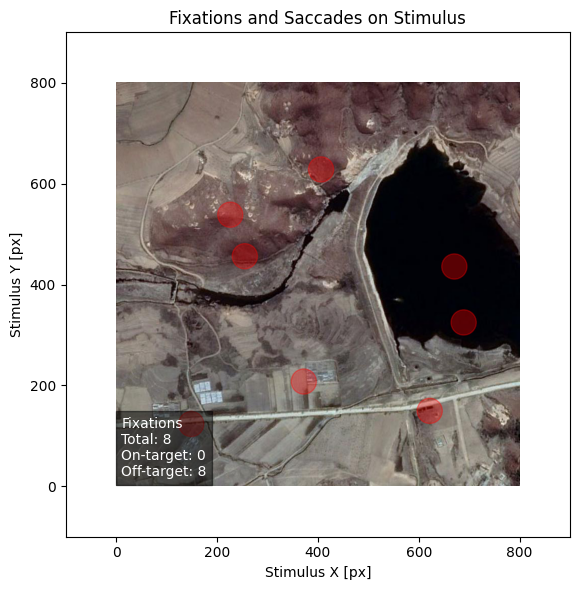

Subject P05
Selected random stimulus for P05: 00114
Fixations: total=9, on-target=7, off-target=2


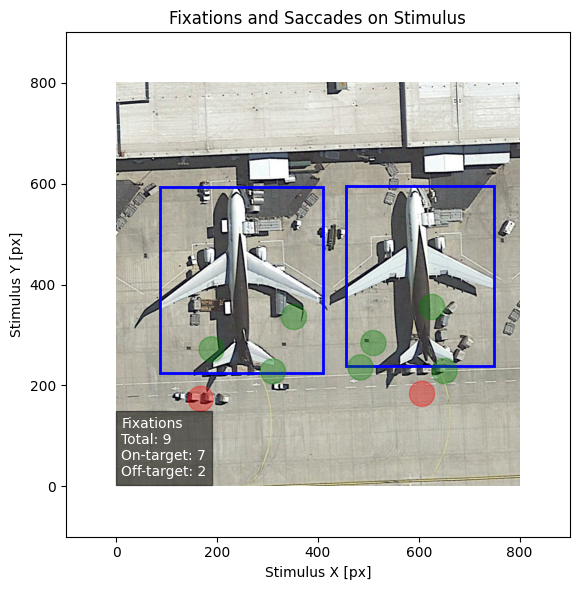

Subject P07
Selected random stimulus for P07: 04565
Fixations: total=3, on-target=3, off-target=0


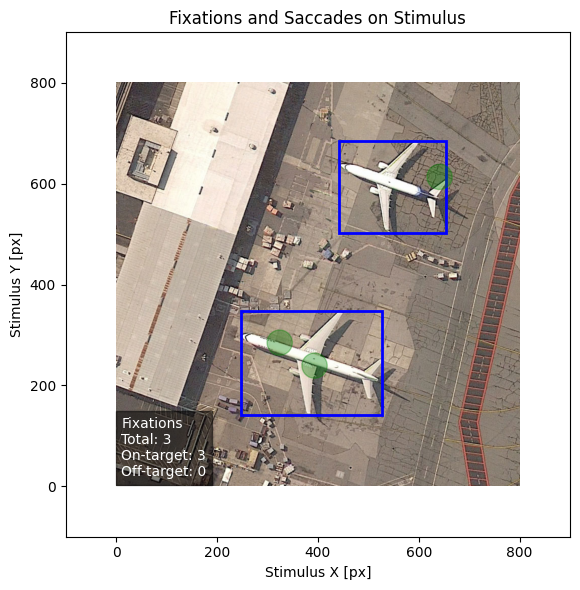

Subject P09
Selected random stimulus for P09: 02030
Fixations: total=7, on-target=5, off-target=2


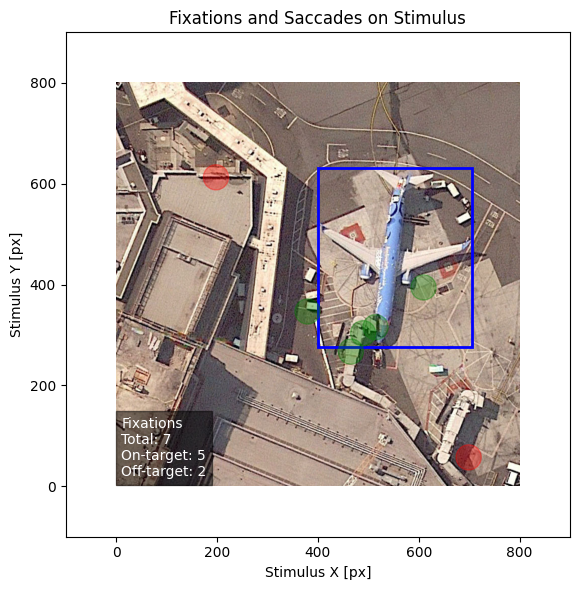

Subject P10
Selected random stimulus for P10: 11064
Fixations: total=9, on-target=0, off-target=9


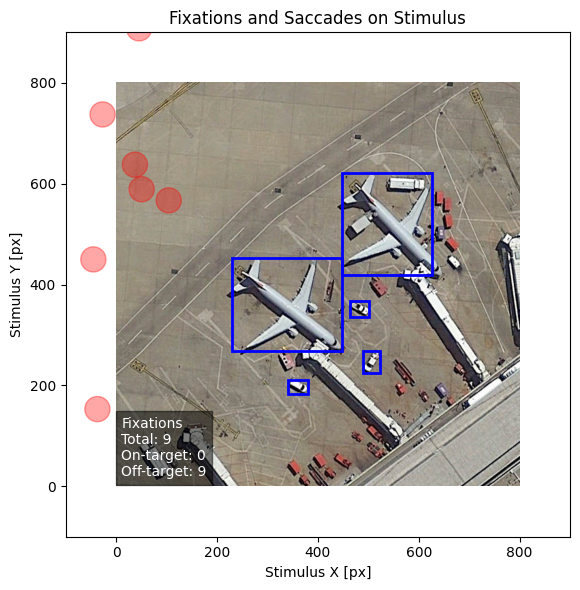

Subject P12
Selected random stimulus for P12: 11885
Fixations: total=13, on-target=0, off-target=13


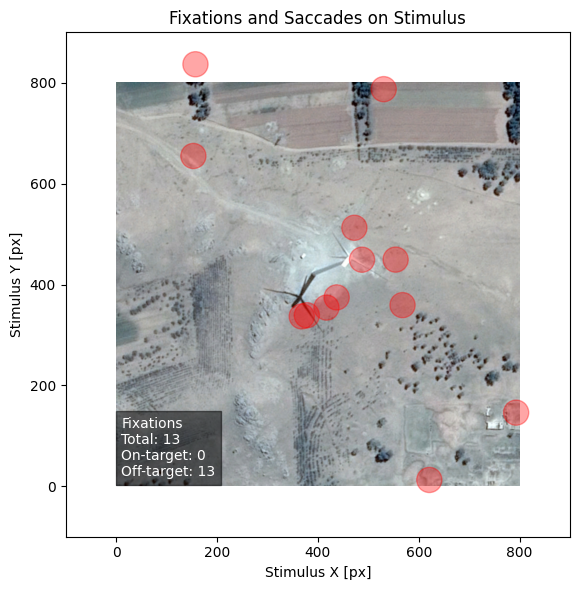

Subject P16
Selected random stimulus for P16: 02371
Fixations: total=7, on-target=6, off-target=1


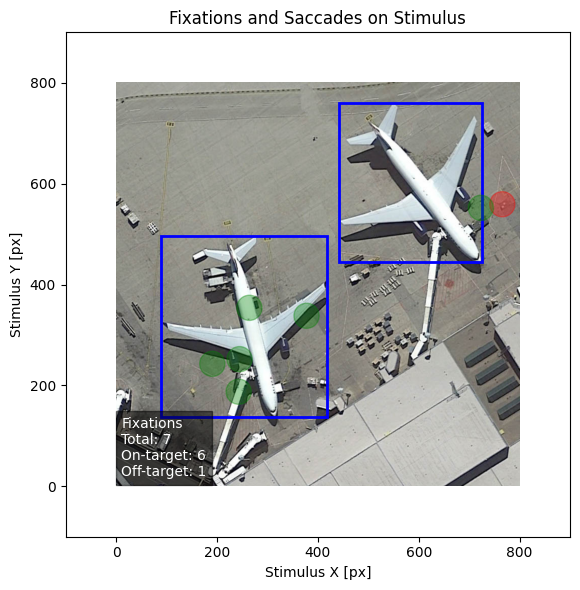

Subject P17
Selected random stimulus for P17: 01038
Fixations: total=10, on-target=10, off-target=0


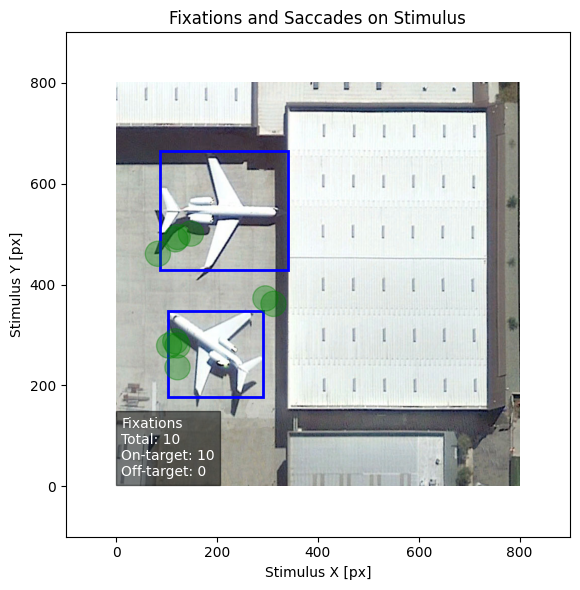

Subject P19
Selected random stimulus for P19: 01077
Fixations: total=9, on-target=3, off-target=6


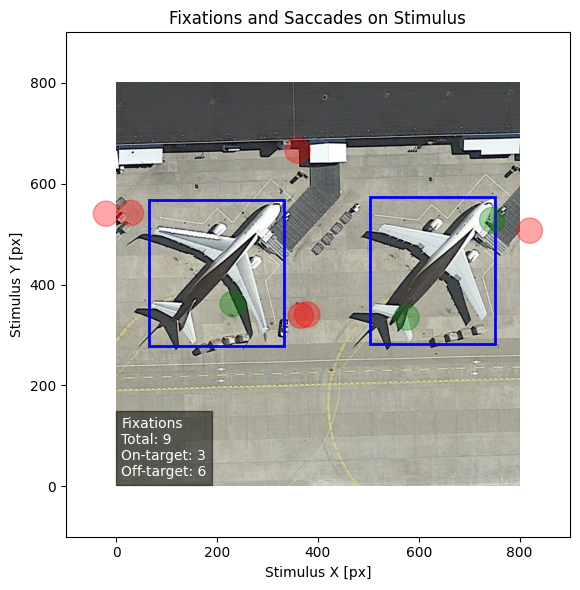

Subject P20
Selected random stimulus for P20: 03118
Fixations: total=11, on-target=5, off-target=6


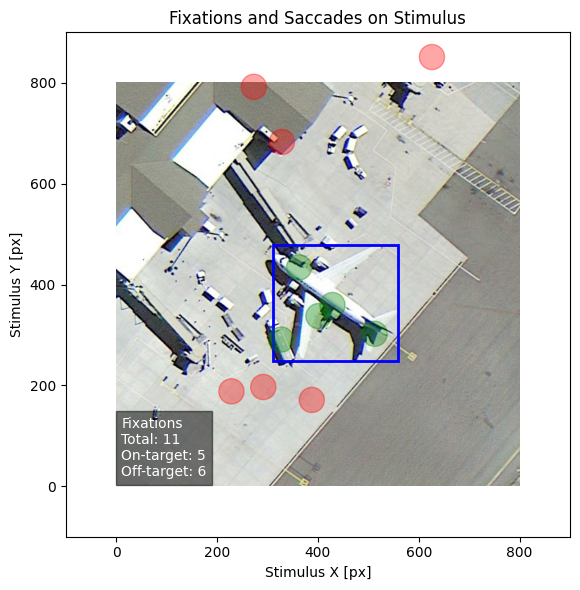

Subject P21
Selected random stimulus for P21: 12886
Fixations: total=10, on-target=7, off-target=3


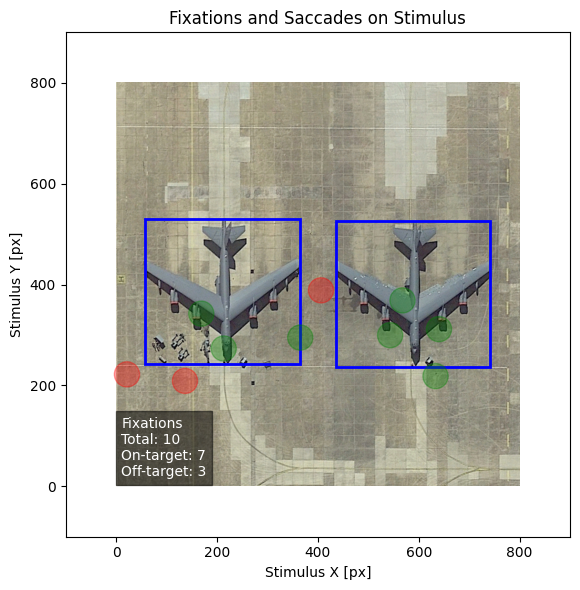

Subject P27
Selected random stimulus for P27: 10711
Fixations: total=5, on-target=4, off-target=1


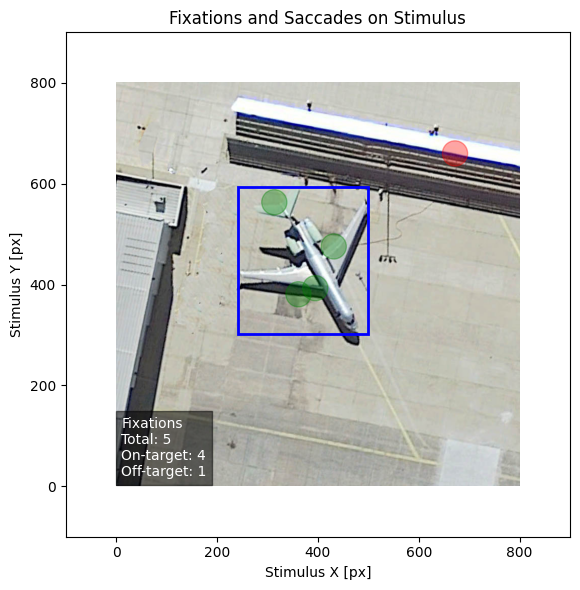

Subject P28
Selected random stimulus for P28: 17775
Fixations: total=5, on-target=1, off-target=4


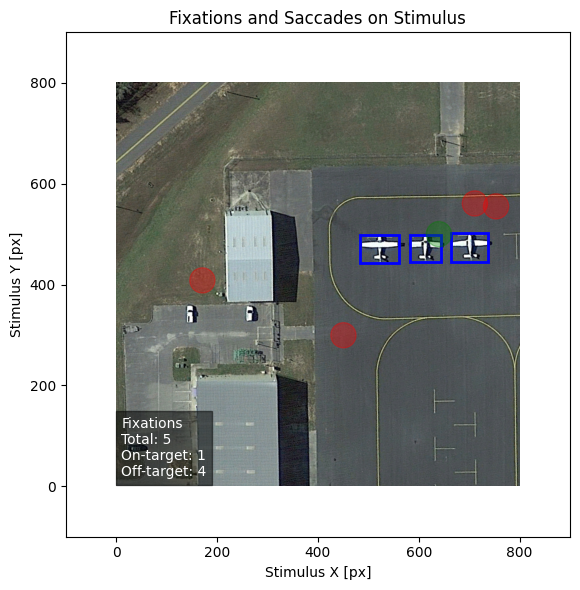

Subject P30
Selected random stimulus for P30: 08607
Fixations: total=9, on-target=4, off-target=5


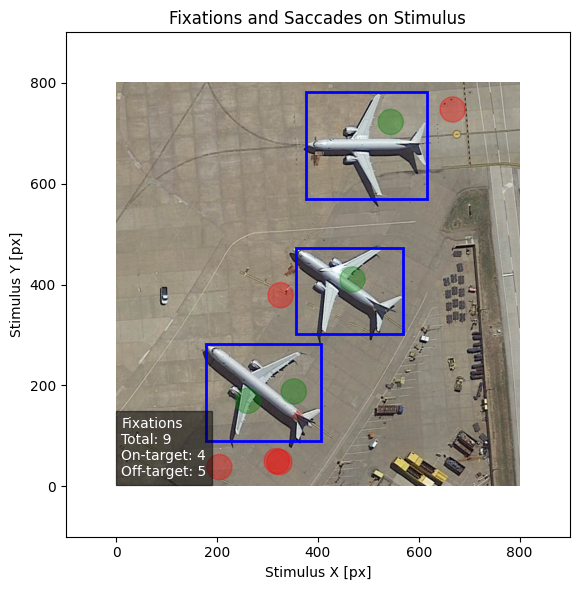

Subject P34
Selected random stimulus for P34: 20918
Fixations: total=9, on-target=1, off-target=8


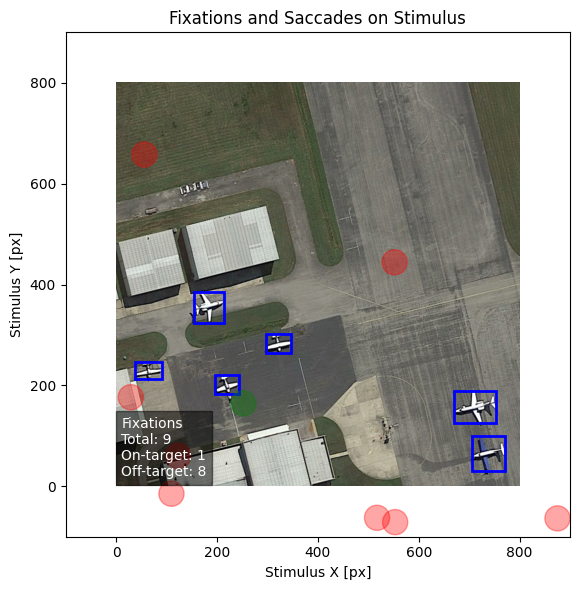

Subject P38
Selected random stimulus for P38: 13845
Fixations: total=10, on-target=1, off-target=9


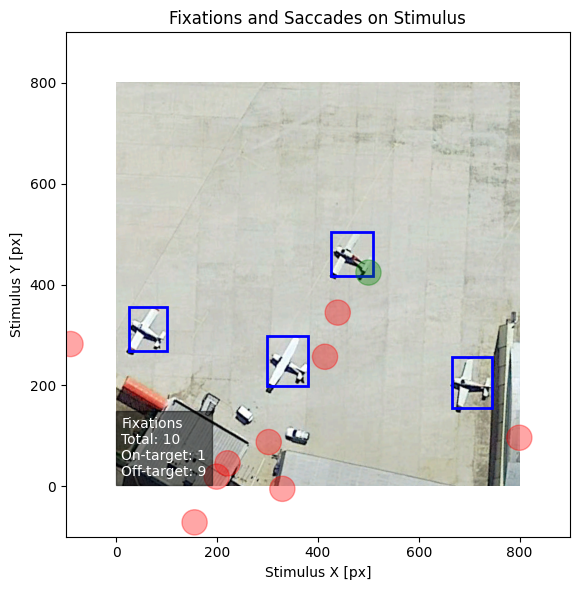

In [36]:
for subj in SUBJECTS:
    print(f"Subject {subj}")
    plot_stimulus_for_subject(subj, also_gaze=False, stimulus=None)

### Check for zero fixations 

Above some images didnt show any fixations, so we check how many trials without fixations stimuli exist per subject. A look at the data tells that some subjects have messed up data. That is, for the Exe tracking many values are missing for some stimuli, therefore we can not use it for further analysis. Subjects with a zero fixation rate above 5% will be removed from the final set of participants.

In [6]:
summary_rows = []
for subj in ALL_SUBJECTS:
    events = load_events(subj)
    available = set(list_available_stimuli(subj))
    event_stims = set(events['stimulus'].dropna().unique().tolist())
    candidate_stims = sorted(event_stims & available)

    zero_fix_stims = []
    for stim in candidate_stims:
        evs = events[events['stimulus'] == stim]
        fix = evs[evs['event_type'] == 'Fixation']
        if len(fix) == 0:
            zero_fix_stims.append(stim)

    total = len(candidate_stims)
    zero_count = len(zero_fix_stims)
    pct_zero = (zero_count / total * 100.0) if total > 0 else 0.0

    summary_rows.append({
        'subject': subj,
        'stimuli': total,
        'zero_fixations': zero_count,
        'pct_zero_fix': round(pct_zero, 1)
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,subject,stimuli,zero_fixations,pct_zero_fix
0,P01,501,0,0.0
1,P02,501,1,0.2
2,P03,501,315,62.9
3,P04,501,287,57.3
4,P05,501,17,3.4
5,P06,501,0,0.0
6,P07,501,0,0.0
7,P08,501,282,56.3
8,P09,501,0,0.0
9,P10,501,0,0.0


In [8]:
# Subjects with >5% zero-fixations
summary_df.loc[summary_df['pct_zero_fix'] > 5, 'subject'].tolist()

['P03', 'P04', 'P08', 'P13', 'P18', 'P22']

### Check fixation duration stats

In [17]:
import pandas as pd

all_fixations = []

for subj in SUBJECTS:
    events = load_events(subj)
    fixations = events[events["event_type"] == "Fixation"].copy()
    fixations["subject_id"] = subj
    all_fixations.append(fixations)

fixations_df = pd.concat(all_fixations, ignore_index=True)


In [19]:
fix_on  = fixations_df[fixations_df["fixation_on_airplane"] == True]
fix_off = fixations_df[fixations_df["fixation_on_airplane"] == False]


In [20]:
def describe_duration(df):
    return pd.Series({
        "count": len(df),
        "mean_ms": df["duration_ms"].mean(),
        "median_ms": df["duration_ms"].median(),
        "std_ms": df["duration_ms"].std(),
        "min_ms": df["duration_ms"].min(),
        "max_ms": df["duration_ms"].max(),
    })


In [ ]:
summary = (
    fixations_df
    .groupby("fixation_on_airplane")
    .apply(describe_duration)
)

summary.index = ["Off airplane", "On airplane"]
print(summary.round(2))

                count  mean_ms  median_ms    std_ms  min_ms      max_ms
Off airplane  35038.0   375.68     228.13  10459.20   66.73  1883501.96
On airplane   27491.0   565.41     267.91  18930.82   64.69  1821083.11


In [29]:
all_events = []

for subj in SUBJECTS:
    events = load_events(subj)
    events["subject_id"] = subj
    all_events.append(events)

df = pd.concat(all_fixations, ignore_index=True)


In [30]:
import pandas as pd
import numpy as np

# --------------------------
# Load CSV
# --------------------------

# Sort by stimulus and start_time to keep temporal order
df = df.sort_values(["stimulus", "start_time"]).reset_index(drop=True)

# --------------------------
# Compute saccade amplitude & velocity
# --------------------------
saccades = df[df["event_type"] == "Saccade"].copy()

# Compute only if coordinates exist
def compute_saccade_features(row):
    if pd.notna(row["start_x"]) and pd.notna(row["end_x"]):
        dx = row["end_x"] - row["start_x"]
        dy = row["end_y"] - row["start_y"]
        amp = np.sqrt(dx**2 + dy**2)
        vel = amp / row["duration_ms"] if row["duration_ms"] > 0 else np.nan
    else:
        amp = np.nan
        vel = np.nan
    return pd.Series({"sacc_amp": amp, "sacc_vel": vel})

saccades[["sacc_amp", "sacc_vel"]] = saccades.apply(compute_saccade_features, axis=1)

# --------------------------
# Prepare fixations
# --------------------------
fixations = df[df["event_type"] == "Fixation"].copy()
fixations["prev_sacc_amp"] = np.nan
fixations["prev_sacc_vel"] = np.nan
fixations["next_sacc_amp"] = np.nan
fixations["next_sacc_vel"] = np.nan

# --------------------------
# Add previous & next saccade info per stimulus
# --------------------------
for stim in df["stimulus"].unique():
    stim_events = df[df["stimulus"] == stim].sort_values("start_time").reset_index()
    stim_sacc = saccades[saccades["stimulus"] == stim]

    fix_locs = stim_events[stim_events["event_type"] == "Fixation"].index

    for idx in fix_locs:
        # Previous saccade
        prev_sacc_idx = stim_events.loc[:idx-1][stim_events["event_type"] == "Saccade"].index
        if len(prev_sacc_idx) > 0:
            prev_idx = prev_sacc_idx[-1]
            srow = stim_sacc[stim_sacc["start_time"] == stim_events.loc[prev_idx, "start_time"]]
            if not srow.empty:
                fixations.loc[stim_events.loc[idx, "index"], "prev_sacc_amp"] = srow["sacc_amp"].values[0]
                fixations.loc[stim_events.loc[idx, "index"], "prev_sacc_vel"] = srow["sacc_vel"].values[0]

        # Next saccade
        next_sacc_idx = stim_events.loc[idx+1:][stim_events["event_type"] == "Saccade"].index
        if len(next_sacc_idx) > 0:
            next_idx = next_sacc_idx[0]
            srow = stim_sacc[stim_sacc["start_time"] == stim_events.loc[next_idx, "start_time"]]
            if not srow.empty:
                fixations.loc[stim_events.loc[idx, "index"], "next_sacc_amp"] = srow["sacc_amp"].values[0]
                fixations.loc[stim_events.loc[idx, "index"], "next_sacc_vel"] = srow["sacc_vel"].values[0]

# --------------------------
# Descriptive statistics
# --------------------------
features = ["duration_ms", "prev_sacc_amp", "prev_sacc_vel", "next_sacc_amp", "next_sacc_vel"]
summary = fixations.groupby("fixation_on_airplane")[features].agg(["count","mean","median","std","min","max"])
summary.index = ["Off airplane","On airplane"]
print(summary.round(2))

             duration_ms                                               \
                   count    mean  median       std    min         max   
Off airplane       35038  375.68  228.13  10459.20  66.73  1883501.96   
On airplane        27491  565.41  267.91  18930.82  64.69  1821083.11   

             prev_sacc_amp                          ... next_sacc_amp          \
                     count    mean  median     std  ...        median     std   
Off airplane         34450  185.12  129.21  209.02  ...        121.78  207.06   
On airplane          27154  132.85   76.02  168.79  ...         73.04  161.72   

                           next_sacc_vel                                    
              min      max         count   mean median    std  min     max  
Off airplane  0.0  2016.81         24762  12.54  12.03  13.02  0.0  394.98  
On airplane   0.0  1596.91         17470  11.37  10.76  12.87  0.0  336.33  

[2 rows x 30 columns]
